# 08 · Elo ratings: do they add information to the models?

**Question:** an Elo rating summarises a club's strength in one number that moves after every
result. Our models already use form, season-to-date and previous-season features. Do Elo ratings
tell them anything new? The goal is not just to compute ratings, but to test whether adding them
improves out-of-sample predictions.

**Method in one paragraph:** ratings are computed match by match from results strictly before
each match (`src/elo.py`). Then the commit-10 walk-forward backtest (2018-19 to 2024-25) is run
twice for each model, with identical folds, tuning procedure and fixtures:
- **Control:** the existing feature sets (`all`, 50 features; `compact`, 22).
- **Elo:** the same sets plus `home_elo`, `away_elo` and `elo_difference` (`all_elo`, 53;
  `compact_elo`, 25).

In every fold the feature set and the hyperparameters are chosen on S-1 after training on
seasons up to S-2. The choice is then refitted on seasons up to S-1 and scored on S. The
2025-26 validation season and the 2026-27 holdout play no part.

## 1. The Elo system

Every club has a rating; 1500 is the league average. Before a match between a home and an away
club:

```
E_home = 1 / (1 + 10 ** ((R_away - R_home - home_advantage) / 400))      expected score of the home side
E_away = 1 - E_home
```

After the match, with the home side's actual score `S_home` = 1 (win), 0.5 (draw) or 0 (loss):

```
R_home_new = R_home + K * (S_home - E_home)
R_away_new = R_away - K * (S_home - E_home)        (the same as R_away + K * (S_away - E_away))
```

The home side gains exactly what the away side loses, so a match never creates or destroys
rating points. A surprising result (low `E` for the winner) moves the ratings a lot; an expected
one moves them little.

**What `E_home` is not.** It is an expected *score* in which a draw counts as half a win. It is
not the probability of a home win: football has three outcomes, and `E_home` mixes the win and
draw chances. It is kept as a descriptive column (`home_elo_expected`) and is **not** a model
feature.

### No leakage: one date at a time

1. All matches on a calendar date first receive both clubs' pre-match ratings, computed from
   results **strictly before** that date.
2. Only then are that date's results applied, each computed from the pre-date ratings.

As a result, a match never sees its own result, matches on the same day never see each other,
and a later result can never change an earlier rating. The same rule (strictly earlier dates)
governs the existing 50 features.

## 2. Settings and assumptions

| Setting | Value | Meaning |
|---|---|---|
| Initial rating | 1500 | Every club in the first season of the data (1993-94); also the league average |
| K-factor | 20 | Maximum rating change from one match is 20 points |
| Home advantage | 60 | Added to the home side's rating when computing `E_home` |
| Summer regression | 30% toward 1500 | `R = 1500 + 0.7 * (R - 1500)` before each new season |

These are **predetermined experimental defaults**. They were fixed before the experiment was
run and were not tuned on any season, so no evaluation season influenced them. Whether other
values would work better is an open question (see the limitations).

**Clubs without usable history** (documented policy, also fixed in advance):
- **1993-94:** every club starts at 1500, because nothing earlier is known.
- **Promoted clubs:** we only have Serie A results, so nothing is invented about their Serie B
  season. A promoted club enters at the **mean rating of the clubs that left the league** that
  summer, after regression. It is assumed to be as strong as the clubs it replaces, and the
  league average stays at 1500.
- **Clubs returning after relegation:** their old rating is **discarded**. We cannot assume a club
  kept its strength while away, so it enters exactly like a newly promoted club. This mirrors the
  "spells" of `src/feature_engineering.py`.
- Which clubs play in a season is known before it starts, so entry ratings use no results from
  the season being rated.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MultipleLocator, PercentFormatter

from src.backtest import BACKTEST_DIR, BACKTEST_SEASONS, BASELINE, METRICS, common_fixtures, load_backtest, \
    pooled_metrics, season_metrics, seasonal_bootstrap
from src.bookmaker import BOOKMAKER_LABEL
from src.config import FIGURES_DIR
from src.elo import DEFAULT_SETTINGS, ELO_COLUMNS, expected_score, rating_change, ratings_before, run_elo
from src.elo_experiment import (
    ELO_DIR, ELO_FEATURE_SETS, FAMILY_WISE_ALPHA, check_elo_is_past_only, comparison_table, decision,
    load_elo_experiment, model_pairs, paired_intervals, run_elo_backtest, save_elo_experiment, subgroup_intervals,
    subgroup_metrics,
)
from src.feature_engineering import FEATURE_COLUMNS, load_features
from src.models import MODEL_SPECS
from src.preprocessing import load_matches
from src.train import VALIDATION_SEASON, season_name

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

features = load_features()
matches = load_matches()
settings = DEFAULT_SETTINGS
pre_match, history, transitions = run_elo(features, settings)
rated = pd.concat([features, pre_match], axis=1)

# The 50 original features are untouched, and no rating depends on a later season
assert rated[FEATURE_COLUMNS].equals(features[FEATURE_COLUMNS])
check_elo_is_past_only(features, range(int(features["season_start"].min()), int(features["season_start"].max()) + 1))
print(f"{len(rated):,} matches rated, {rated['season_start'].min()}-{rated['season_start'].max()}; "
      "every rating uses earlier results only")

11,826 matches rated, 1993-2026; every rating uses earlier results only


In [2]:
# The walk-forward experiment: load the saved run (python -m src.elo_experiment), or run it here
if (ELO_DIR / "predictions.csv").exists():
    experiment = load_elo_experiment()
    saved = json.loads((ELO_DIR / "settings.json").read_text())
    assert saved["elo"] == settings.as_dict(), "saved results were produced with different Elo settings"
    saved_elo = pd.read_csv(ELO_DIR / "elo_features.csv", parse_dates=["date"])
    assert np.allclose(saved_elo[ELO_COLUMNS].to_numpy(), pre_match[ELO_COLUMNS].to_numpy(), rtol=0, atol=1e-9)
    print("Loaded the saved experiment from outputs/elo/ (ratings reproduced exactly)")
else:
    start = time.time()
    experiment = run_elo_backtest(features, matches, progress=print)
    save_elo_experiment(experiment, features)
    print(f"Experiment finished in {(time.time() - start) / 60:.1f} minutes")

predictions = experiment.predictions
MODELS = [spec.label for spec in MODEL_SPECS.values()]
PAIRS = model_pairs()  # (Elo arm, control) per model
ELO_LABELS = [elo for elo, _ in PAIRS]
SEASON_LABELS = {s: season_name(s) for s in BACKTEST_SEASONS}
print("Forecasts:", ", ".join(predictions["forecast"].unique()))

Loaded the saved experiment from outputs/elo/ (ratings reproduced exactly)
Forecasts: Logistic Regression, Random Forest, XGBoost, Baseline, Bookmaker (Bet365), Logistic Regression + Elo, Random Forest + Elo, XGBoost + Elo


In [3]:
# --- Chart style (same as notebooks 01-07) -------------------------------------
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE_LINE, NEUTRAL = "#e1e0d9", "#c3c2b7", "#a3a29b"
MODEL_COLORS = {"Logistic Regression": "#2a78d6", "Random Forest": "#eb6834", "XGBoost": "#1baf7a",
                BOOKMAKER_LABEL: "#eda100", BASELINE: NEUTRAL}
CLUB_COLORS = {"Juventus": "#2a78d6", "Inter": "#eb6834", "Milan": "#1baf7a", "Napoli": "#eda100",
               "Roma": "#e87ba4", "Lazio": "#008300"}


def style_axes(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE_LINE)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)


def set_title(ax, title, subtitle=None, size=12):
    ax.set_title(title, loc="left", fontsize=size, color=INK, pad=26 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=9, color=INK_2, va="bottom")


def save_figure(fig, name):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / name, dpi=150, facecolor=SURFACE, bbox_inches="tight")

In [4]:
t = transitions.set_index("season_start")
summer = t.loc[t.index >= 2016, ["clubs", "leavers", "entrants", "entry_rating", "mean_rating"]].copy()
summer.index = summer.index.map(season_name)
summer["leavers"] = summer["leavers"].str.join(", ")
summer["entrants"] = summer["entrants"].str.join(", ")
summer.style.format({"entry_rating": "{:.1f}", "mean_rating": "{:.2f}"}).set_caption(
    "Season starts: clubs that left, clubs that entered, and the entry rating given to the entrants")

,clubs,leavers,entrants,entry_rating,mean_rating
season_start,,,,,
2016-17,20,"Carpi, Frosinone, Verona","Cagliari, Crotone, Pescara",1434.9,1499.91
2017-18,20,"Empoli, Palermo, Pescara","Benevento, Spal, Verona",1406.8,1499.93
2018-19,20,"Benevento, Crotone, Verona","Empoli, Frosinone, Parma",1400.9,1499.95
2019-20,20,"Chievo, Empoli, Frosinone","Brescia, Lecce, Verona",1411.8,1499.97
2020-21,20,"Brescia, Lecce, Spal","Benevento, Crotone, Spezia",1397.2,1499.98
2021-22,20,"Benevento, Crotone, Parma","Empoli, Salernitana, Venezia",1394.9,1499.98
2022-23,20,"Cagliari, Genoa, Venezia","Cremonese, Lecce, Monza",1418.7,1499.99
2023-24,20,"Cremonese, Sampdoria, Spezia","Cagliari, Frosinone, Genoa",1409.9,1499.99
2024-25,20,"Frosinone, Salernitana, Sassuolo","Como, Parma, Venezia",1412.5,1499.99


**Interpretation**

- **Promoted clubs start well below average.** Since 2018-19 the entry rating has been between
  about 1393 and 1419, because the clubs that go down are usually the weakest ones. Starting
  promoted clubs at 1500 would have rated them like a mid-table side.
- **The league average stays at 1500,** because the entrants inherit exactly the average of the
  clubs they replace. The only exception is the 2004-05 expansion from 18 to 20 clubs: five clubs
  came up for three that went down, and the average dipped to about 1493 before the summer
  regression pulled it back (1499.95 by 2018-19).

## 3. How ratings move after a match

The change depends on the rating gap and on the result. Below, "rating gap" is the home club's
rating minus the away club's, before the 60-point home advantage is added.

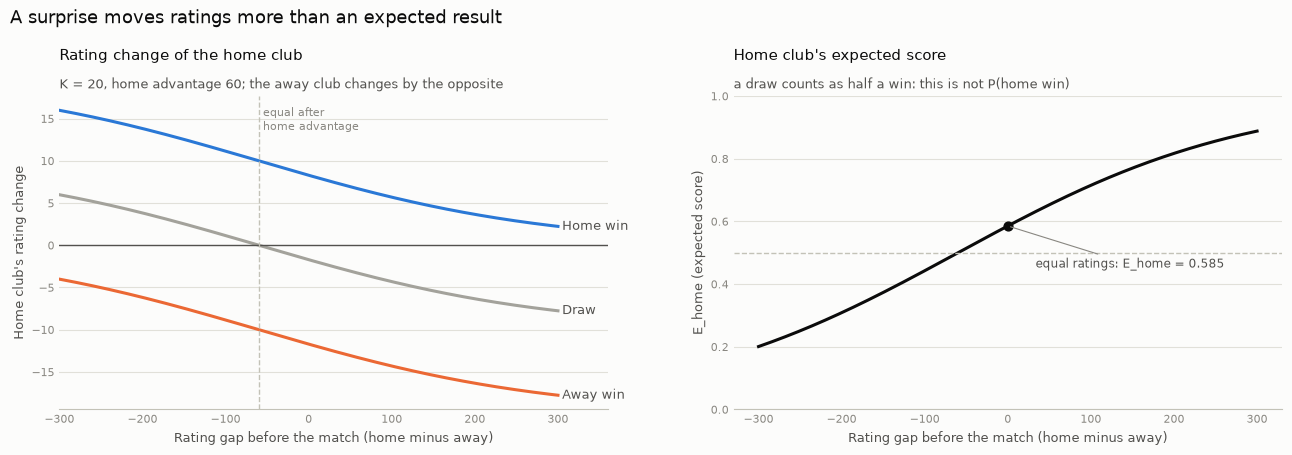

In [5]:
gap = np.linspace(-300, 300, 301)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), facecolor=SURFACE)

ax = axes[0]
for score, label, color in ((1.0, "Home win", "#2a78d6"), (0.5, "Draw", NEUTRAL), (0.0, "Away win", "#eb6834")):
    change = settings.k_factor * (score - expected_score(1500 + gap, 1500, settings.home_advantage))
    ax.plot(gap, change, color=color, linewidth=2.2)
    ax.text(305, change[-1], label, va="center", fontsize=9, color=INK_2)
ax.axhline(0, color=INK_2, linewidth=1)
ax.axvline(-settings.home_advantage, color=BASELINE_LINE, linewidth=1, linestyle="--")
ax.text(-settings.home_advantage + 5, 16.5, "equal after\nhome advantage", fontsize=8, color=MUTED, va="top")
ax.set_xlabel("Rating gap before the match (home minus away)", fontsize=9, color=INK_2)
ax.set_ylabel("Home club's rating change", fontsize=9, color=INK_2)
ax.set_xlim(-300, 360)
style_axes(ax)
set_title(ax, "Rating change of the home club", "K = 20, home advantage 60; the away club changes by the opposite",
          size=11)

ax = axes[1]
e = expected_score(1500 + gap, 1500, settings.home_advantage)
ax.plot(gap, e, color=INK, linewidth=2.2)
ax.axhline(0.5, color=BASELINE_LINE, linewidth=1, linestyle="--")
ax.scatter([0], [expected_score(1500, 1500, 60)], s=40, color=INK, zorder=3)
ax.annotate(f"equal ratings: E_home = {expected_score(1500, 1500, 60):.3f}", (0, expected_score(1500, 1500, 60)),
            xytext=(20, -30), textcoords="offset points", fontsize=8.5, color=INK_2,
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))
ax.set_xlabel("Rating gap before the match (home minus away)", fontsize=9, color=INK_2)
ax.set_ylabel("E_home (expected score)", fontsize=9, color=INK_2)
ax.set_ylim(0, 1)
style_axes(ax)
set_title(ax, "Home club's expected score", "a draw counts as half a win: this is not P(home win)", size=11)
fig.suptitle("A surprise moves ratings more than an expected result", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=4)
save_figure(fig, "37_elo_rating_update.png")
plt.show()

In [6]:
# A worked example: the opening matchday of 2018-19
opening = rated[rated["season_start"] == 2018].nsmallest(10, "date")
example = opening[["date", "home_team", "away_team", "result", "home_elo", "away_elo", "home_elo_expected"]].copy()
score = example["result"].map({"H": 1.0, "D": 0.5, "A": 0.0})
example["home_change"] = settings.k_factor * (score - example["home_elo_expected"])
example.style.format({"home_elo": "{:.1f}", "away_elo": "{:.1f}", "home_elo_expected": "{:.3f}",
                      "home_change": "{:+.2f}", "date": "{:%Y-%m-%d}"}).hide(axis="index")

date,home_team,away_team,result,home_elo,away_elo,home_elo_expected,home_change
2018-08-18,Chievo,Juventus,A,1453.2,1661.7,0.298,-5.97
2018-08-18,Lazio,Napoli,A,1562.0,1640.8,0.473,-9.46
2018-08-19,Bologna,Spal,A,1430.9,1450.4,0.558,-11.16
2018-08-19,Empoli,Cagliari,H,1400.9,1450.3,0.515,+9.70
2018-08-19,Parma,Udinese,D,1400.9,1440.3,0.530,-0.59
2018-08-19,Sassuolo,Inter,H,1482.4,1560.1,0.475,+10.51
2018-08-19,Torino,Roma,A,1516.1,1605.0,0.458,-9.17
2018-08-20,Atalanta,Frosinone,H,1542.2,1400.9,0.761,+4.78
2018-08-25,Juventus,Lazio,H,1667.7,1552.5,0.733,+5.35
2018-08-25,Napoli,Milan,H,1650.2,1548.2,0.718,+5.65


**Interpretation**

- **Between equal clubs** (same rating, so the home side expects 0.585), a home win is worth
  +8.3 points, a draw −1.7 and an away win −11.7 for the home club. The away club moves by the
  opposite amount.
- **A draw is not neutral at home:** because home advantage makes the home side the favourite, a
  draw costs it points unless the visitor is about 60 points stronger.
- **Surprises move ratings most.** A home side 200 points stronger gains only about +3.7 for a
  win but loses about −16.3 for a defeat.

## 4. Historical ratings of six clubs

Each panel shows one club's rating after every Serie A match (the other five in grey). A gap means
the club was not in Serie A. When it came back, it re-entered at the rating of the clubs it
replaced, as the policy above prescribes.

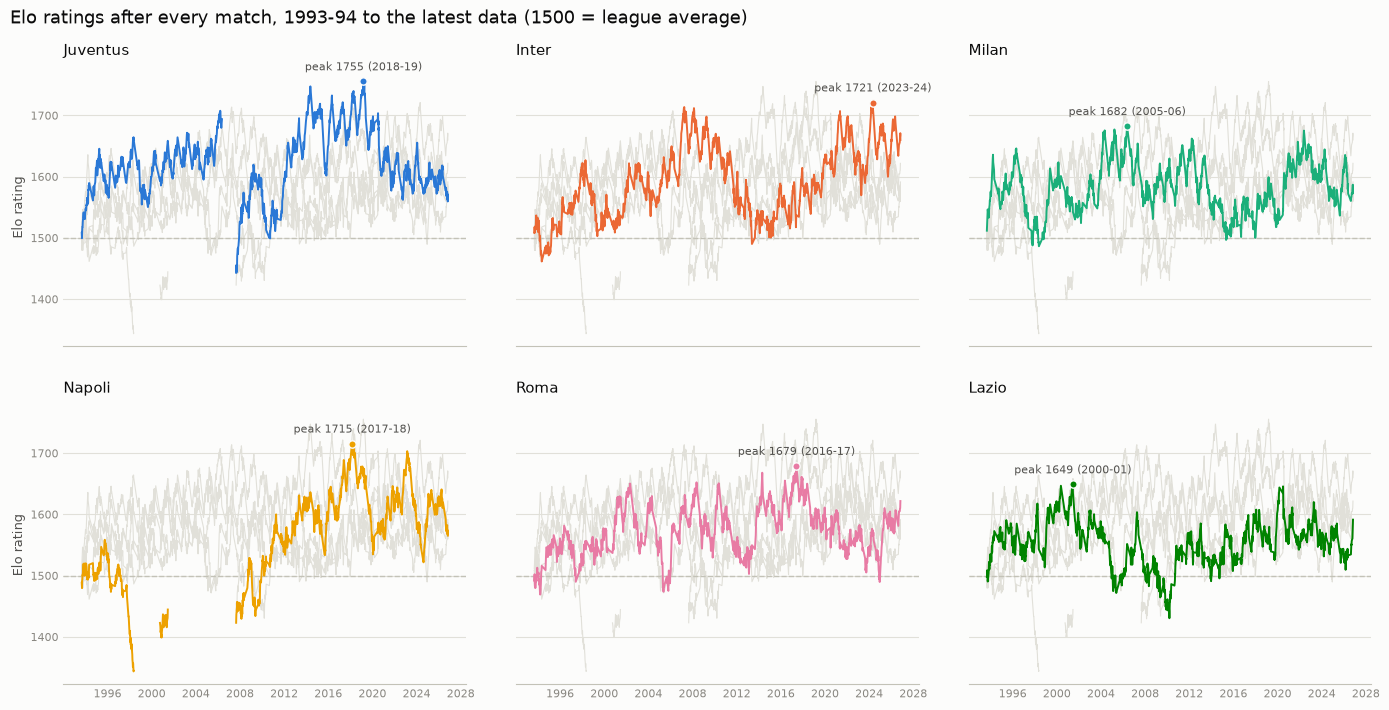

In [7]:
clubs = list(CLUB_COLORS)
played = history[history["played"]]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.2), facecolor=SURFACE, sharex=True, sharey=True)


def club_lines(team):
    rows = played[played["team"] == team].sort_values("date")
    # break the line between seasons the club missed
    new_spell = rows["season_start"].diff().fillna(1) > 1
    for _, spell in rows.groupby(new_spell.cumsum()):
        yield spell["date"], spell["rating_after"]


for ax, club in zip(axes.ravel(), clubs):
    for other in clubs:
        if other != club:
            for dates, values in club_lines(other):
                ax.plot(dates, values, color=GRID, linewidth=0.8, zorder=1)
    for dates, values in club_lines(club):
        ax.plot(dates, values, color=CLUB_COLORS[club], linewidth=1.4, zorder=3)
    ax.axhline(1500, color=BASELINE_LINE, linewidth=1, linestyle="--", zorder=2)
    peak = played[played["team"] == club].nlargest(1, "rating_after").iloc[0]
    ax.scatter(peak["date"], peak["rating_after"], s=28, color=CLUB_COLORS[club], edgecolors=SURFACE, zorder=4)
    ax.annotate(f"peak {peak['rating_after']:.0f} ({season_name(peak['season_start'])})",
                (peak["date"], peak["rating_after"]), xytext=(0, 8), textcoords="offset points",
                fontsize=8, color=INK_2, ha="center")
    style_axes(ax)
    set_title(ax, club, size=11)
for ax in axes[:, 0]:
    ax.set_ylabel("Elo rating", fontsize=9, color=INK_2)
fig.suptitle("Elo ratings after every match, 1993-94 to the latest data (1500 = league average)",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(h_pad=2.5, w_pad=2)
save_figure(fig, "38_elo_club_histories.png")
plt.show()

**Interpretation**

- **The ratings follow the familiar story of the league.** Juventus reached the highest rating in
  the data (1755) during their run of titles, peaking in 2018-19. Inter peaked in 2023-24, Napoli
  in 2017-18 and Milan in 2005-06.
- **The return policy is visible.** Juventus spent 2006-07 in Serie B and Napoli missed several
  seasons around 2000-2007. Each came back at the rating of the clubs it replaced (about
  1430) and had to earn its rating back, instead of keeping a rating from before it went
  down.
- **Regression keeps ratings in a band.** Even the strongest clubs rarely stay above 1700 for
  long, because 30% of the gap to 1500 disappears every summer.

## 5. Strongest and weakest clubs at two cutoffs

Each ranking uses **only matches played before the cutoff**:
- **1 August 2018**, just before the first season of the backtest (the end-of-season ratings of
  2017-18, before the summer regression);
- **the latest data date**, which shows the current 2026-27 picture.

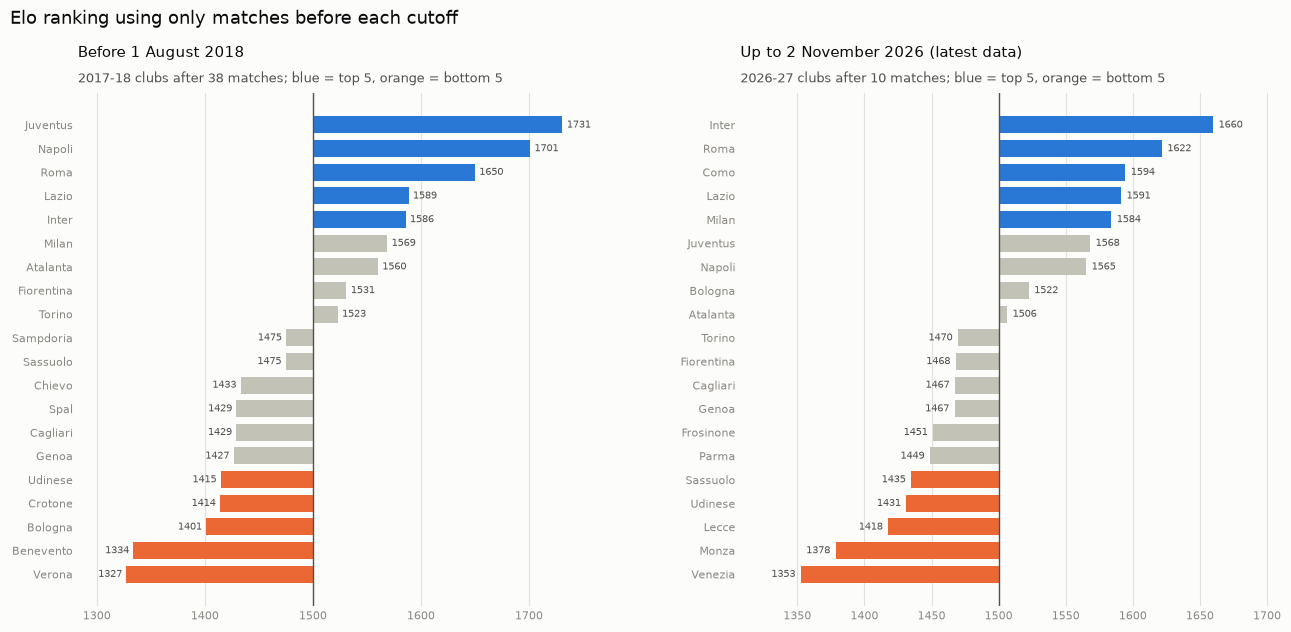

In [8]:
latest_date = rated.loc[rated["result"].notna(), "date"].max()
cutoffs = {"Before 1 August 2018": pd.Timestamp("2018-08-01"),
           f"Up to {latest_date.day} {latest_date:%B %Y} (latest data)": latest_date + pd.Timedelta(days=1)}
tables = {name: ratings_before(features, cutoff) for name, cutoff in cutoffs.items()}

fig, axes = plt.subplots(1, 2, figsize=(13, 6.4), facecolor=SURFACE)
for ax, (name, table) in zip(axes, tables.items()):
    table = table.sort_values("rating")
    n = len(table)
    colors = ["#eb6834" if i < 5 else ("#2a78d6" if i >= n - 5 else BASELINE_LINE) for i in range(n)]
    y = np.arange(n)
    ax.barh(y, table["rating"] - 1500, left=1500, color=colors, height=0.72)
    for yi, (_, row) in zip(y, table.iterrows()):
        offset = 4 if row["rating"] >= 1500 else -4
        ax.text(row["rating"] + offset, yi, f"{row['rating']:.0f}", va="center", fontsize=7.5, color=INK_2,
                ha="left" if offset > 0 else "right")
    ax.axvline(1500, color=INK_2, linewidth=1)
    ax.set_yticks(y, table["team"], fontsize=8.5, color=INK_2)
    ax.set_xlim(table["rating"].min() - 45, table["rating"].max() + 45)
    style_axes(ax, grid="x")
    ax.spines["bottom"].set_visible(False)
    season = season_name(int(table["season_start"].iloc[0]))
    played_n = int(table["matches_this_season"].max())
    set_title(ax, name, f"{season} clubs after {played_n} matches; blue = top 5, orange = bottom 5",
              size=11)
fig.suptitle("Elo ranking using only matches before each cutoff", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=5)
save_figure(fig, "39_elo_ranking_at_cutoffs.png")
plt.show()

**Interpretation**

- **Before 1 August 2018** (end of 2017-18): Juventus (1731), Napoli (1701) and Roma (1650) lead.
  The bottom two, Verona (1327) and Benevento (1334), were the clubs relegated that May.
- **Latest data (10 matches into 2026-27):** Inter (1660), Roma (1622) and Como (1594) lead.
  Juventus are sixth at 1568. Monza (1378) and Venezia (1353), both promoted this summer, have
  fallen below their entry rating of about 1393.
- **Ten matches into a season the rating still leans on last season** (70% of the summer rating
  carries over, and each match moves it by at most 20 points). That is how Elo is designed, and
  it is also why it overlaps with the previous-season features (section 7).

## 6. Rating differences and results

This descriptive analysis uses seasons 1994-95 to 2024-25. 1993-94 is excluded because every
club started it at 1500; 2025-26 and 2026-27 are excluded because they are reserved for the
production models' validation and test.

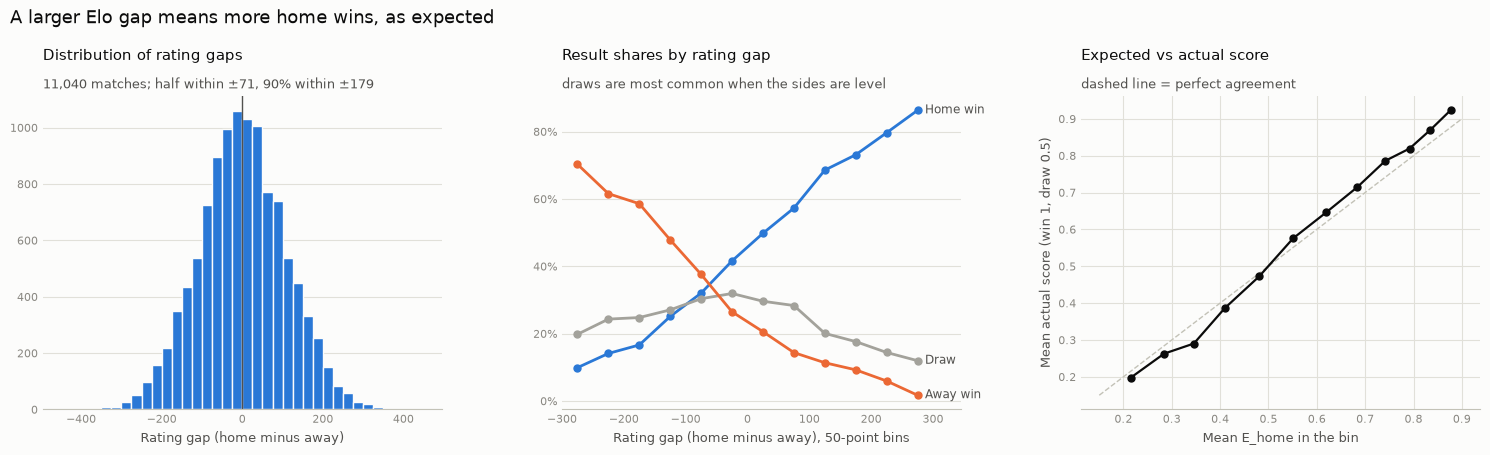

,matches,H,D,A,expected,actual
gap_bin,,,,,,
"(-300, -250]",101,9.9%,19.8%,70.3%,0.215,0.198
"(-250, -200]",255,14.1%,24.3%,61.6%,0.284,0.263
"(-200, -150]",565,16.6%,24.8%,58.6%,0.346,0.290
"(-150, -100]",972,25.1%,27.1%,47.8%,0.410,0.386
"(-100, -50]",1623,32.0%,30.4%,37.6%,0.481,0.472
"(-50, 0]",2055,41.6%,31.9%,26.5%,0.551,0.576
"(0, 50]",2036,49.8%,29.6%,20.6%,0.619,0.646
"(50, 100]",1510,57.3%,28.3%,14.4%,0.684,0.715
"(100, 150]",986,68.6%,20.1%,11.4%,0.742,0.786


In [9]:
desc = rated[(rated["season_start"] > rated["season_start"].min()) & (rated["season_start"] < VALIDATION_SEASON)].copy()
edges = np.arange(-300, 301, 50)
desc["gap_bin"] = pd.cut(desc["elo_difference"].clip(-299.9, 299.9), edges)
by_bin = desc.groupby("gap_bin", observed=True).agg(
    matches=("result", "size"), H=("result", lambda r: (r == "H").mean()),
    D=("result", lambda r: (r == "D").mean()), A=("result", lambda r: (r == "A").mean()),
    expected=("home_elo_expected", "mean"),
    actual=("result", lambda r: r.map({"H": 1.0, "D": 0.5, "A": 0.0}).mean()))
mid = np.array([interval.mid for interval in by_bin.index])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), facecolor=SURFACE)
ax = axes[0]
ax.hist(desc["elo_difference"], bins=np.arange(-450, 451, 25), color="#2a78d6", edgecolor=SURFACE, linewidth=1)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_xlabel("Rating gap (home minus away)", fontsize=9, color=INK_2)
style_axes(ax)
q = desc["elo_difference"].abs().quantile([0.5, 0.9])
set_title(ax, "Distribution of rating gaps",
          f"{len(desc):,} matches; half within ±{q[0.5]:.0f}, 90% within ±{q[0.9]:.0f}", size=11)

ax = axes[1]
for outcome, label, color in (("H", "Home win", "#2a78d6"), ("D", "Draw", NEUTRAL), ("A", "Away win", "#eb6834")):
    ax.plot(mid, by_bin[outcome], color=color, linewidth=2, marker="o", markersize=5)
    ax.text(mid[-1] + 12, by_bin[outcome].iloc[-1], label, va="center", fontsize=8.5, color=INK_2)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Rating gap (home minus away), 50-point bins", fontsize=9, color=INK_2)
ax.set_xlim(-300, 345)
style_axes(ax)
set_title(ax, "Result shares by rating gap", "draws are most common when the sides are level", size=11)

ax = axes[2]
ax.plot([0.15, 0.9], [0.15, 0.9], color=BASELINE_LINE, linewidth=1, linestyle="--")
ax.plot(by_bin["expected"], by_bin["actual"], color=INK, linewidth=1.6, marker="o", markersize=5)
ax.set_xlabel("Mean E_home in the bin", fontsize=9, color=INK_2)
ax.set_ylabel("Mean actual score (win 1, draw 0.5)", fontsize=9, color=INK_2)
style_axes(ax, grid="both")
set_title(ax, "Expected vs actual score", "dashed line = perfect agreement", size=11)
fig.suptitle("A larger Elo gap means more home wins, as expected", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=3.5)
save_figure(fig, "40_elo_differences_and_results.png")
plt.show()
by_bin.style.format({"H": "{:.1%}", "D": "{:.1%}", "A": "{:.1%}", "expected": "{:.3f}", "actual": "{:.3f}"})

**Interpretation**

- **Most matches are fairly even on Elo:** half have a gap within ±71 points and 90% within ±179.
- **Results follow the gap strongly.** The home-win share rises from about 10% when the home club
  is 250–300 points weaker to about 86% when it is 250–300 points stronger.
- **Draws** are most common (about 30%) when the sides are level once home advantage is counted.
  They fall to 12–20% when one side is much stronger.
- **The expected score is close to the actual score,** but strong home sides score slightly more
  than expected and weak ones slightly less. So the rating gaps are a little compressed (K = 20
  and the summer regression shrink them). This does not matter for the models, which learn their
  own scale from the Elo columns.

## 7. Elo versus the existing team-strength features

If Elo mostly repeats what the models already know, it cannot add much. Below, each existing
team-strength feature is turned into a home-minus-away difference and compared with
`elo_difference` (Spearman rank correlation, 1994-95 to 2024-25, matches where both values exist).
The table also shows how often each feature is missing; Elo is never missing.

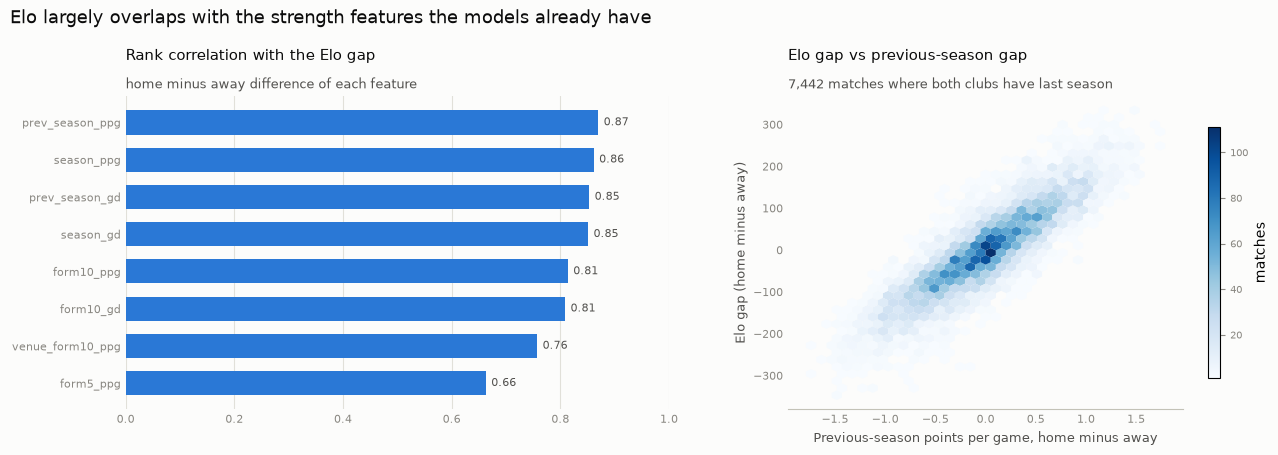

,spearman_with_elo_difference,missing_share
feature (home minus away),,
form5_ppg,0.663,4.5%
venue_form10_ppg,0.757,17.9%
form10_gd,0.809,8.8%
form10_ppg,0.814,8.8%
season_gd,0.851,2.8%
prev_season_gd,0.853,32.6%
season_ppg,0.861,2.8%
prev_season_ppg,0.870,32.6%


In [10]:
strength = ["prev_season_ppg", "prev_season_gd", "season_ppg", "season_gd", "form10_ppg", "form10_gd",
            "form5_ppg", "venue_form10_ppg"]
rows = []
for name in strength:
    diff = desc[f"home_{name}"] - desc[f"away_{name}"]
    rows.append({"feature (home minus away)": name, "spearman_with_elo_difference": diff.corr(desc["elo_difference"],
                 method="spearman"), "missing_share": diff.isna().mean()})
correlations = pd.DataFrame(rows).set_index("feature (home minus away)").sort_values("spearman_with_elo_difference")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), facecolor=SURFACE, gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
y = np.arange(len(correlations))
ax.barh(y, correlations["spearman_with_elo_difference"], color="#2a78d6", height=0.65)
for yi, value in zip(y, correlations["spearman_with_elo_difference"]):
    ax.text(value + 0.01, yi, f"{value:.2f}", va="center", fontsize=8, color=INK_2)
ax.set_yticks(y, correlations.index, fontsize=8.5, color=INK_2)
ax.set_xlim(0, 1)
style_axes(ax, grid="x")
ax.spines["bottom"].set_visible(False)
set_title(ax, "Rank correlation with the Elo gap", "home minus away difference of each feature", size=11)

ax = axes[1]
sample = desc.dropna(subset=["home_prev_season_ppg", "away_prev_season_ppg"])
x = sample["home_prev_season_ppg"] - sample["away_prev_season_ppg"]
hb = ax.hexbin(x, sample["elo_difference"], gridsize=35, cmap="Blues", mincnt=1, linewidths=0)
ax.set_xlabel("Previous-season points per game, home minus away", fontsize=9, color=INK_2)
ax.set_ylabel("Elo gap (home minus away)", fontsize=9, color=INK_2)
style_axes(ax, grid=None)
set_title(ax, "Elo gap vs previous-season gap", f"{len(sample):,} matches where both clubs have last season",
          size=11)
fig.colorbar(hb, ax=ax, shrink=0.8, label="matches").ax.tick_params(labelsize=7, colors=MUTED)
fig.suptitle("Elo largely overlaps with the strength features the models already have",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=4)
save_figure(fig, "41_elo_vs_existing_features.png")
plt.show()
correlations.style.format({"spearman_with_elo_difference": "{:.3f}", "missing_share": "{:.1%}"})

**Interpretation**

- **Elo mostly repeats what the models already know.** The Elo gap has a rank correlation of
  0.87 with the previous-season points gap and 0.86 with the season-to-date points gap. Even
  10-match form correlates at 0.81.
- **What Elo adds** is mainly:
  - **completeness:** it is never missing, while the previous-season gap is missing in 33% of
    matches (promoted clubs and 1993-94) and 10-match form in 9%;
  - **a different weighting:** it adjusts for the strength of each opponent and blends the
    seasons smoothly.
- **Expect a small effect at most:** a feature this correlated with existing features can only
  add a small amount of new information.

## 8. Seven-season comparison: with and without Elo

### 8a. What each fold chose

In each fold, each arm picks its own feature set and hyperparameters from the same grids, using
only earlier seasons. The Elo arm chooses between `all_elo` and `compact_elo`.

In [11]:
SHORT = {"C": "C", "max_depth": "depth", "min_samples_leaf": "leaf", "n_estimators": "trees"}
folds = experiment.folds.copy()
folds["choice"] = folds["feature_set"] + ": " + folds["params"].map(
    lambda p: ", ".join(f"{SHORT.get(k, k)} {v}" for k, v in json.loads(p).items()))
choices = folds.pivot_table(index="season", columns=["model", "arm"], values="choice", aggfunc="first")
choices.index = choices.index.map(SEASON_LABELS)
choices[[(m, a) for m in MODELS for a in ("control", "elo")]]

model   Logistic Regression                                        Random Forest                                                        XGBoost                                 
arm                 control                    elo                       control                               elo                      control                              elo
season                                                                                                                                                                          
2018-19         all: C 0.01     compact_elo: C 1.0  compact: depth None, leaf 20  compact_elo: depth None, leaf 20      all: depth 2, trees 500      all_elo: depth 2, trees 500
2019-20       all: C 0.0003      all_elo: C 0.0003        all: depth 12, leaf 10     compact_elo: depth 6, leaf 10      all: depth 4, trees 100      all_elo: depth 4, trees 100
2020-21      compact: C 0.1     compact_elo: C 0.1  compact: depth None, leaf 50  compact_elo: depth None, leaf 20  compact: depth 3, trees 250  compact_elo: depth 4, trees 100
2021-22          all: C 1.0        all_elo: C 0.01  compact: depth None, leaf 10  compact_elo: depth None, leaf 10      all: depth 4, trees 250      all_elo: depth 3, trees 250
2022-23   compact: C 0.0003  compact_elo: C 0.0003  compact: depth None, leaf 10      all_elo: depth None, leaf 10      all: depth 4, trees 250      all_elo: depth 3, trees 250
2023-24      compact: C 1.0       all_elo: C 0.001      all: depth None, leaf 10         all_elo: depth 6, leaf 10      all: depth 2, trees 250      all_elo: depth 2, trees 250
2024-25        all: C 0.001       all_elo: C 0.001        all: depth 12, leaf 10      all_elo: depth None, leaf 10  compact: depth 2, trees 250      all_elo: depth 4, trees 100

In [12]:
# The control arm reproduces the commit-10 backtest exactly (same folds, same code path)
if (BACKTEST_DIR / "predictions.csv").exists():
    commit10 = load_backtest().predictions
    keys = ["season", "forecast", "date", "home_team", "away_team"]
    ours = predictions[predictions["forecast"].isin(MODELS)].sort_values(keys).reset_index(drop=True)
    theirs = commit10[commit10["forecast"].isin(MODELS)].sort_values(keys).reset_index(drop=True)
    same = ours[keys].astype(str).equals(theirs[keys].astype(str))
    gap = np.abs(ours[["H", "D", "A"]].to_numpy() - theirs[["H", "D", "A"]].to_numpy()).max() if same else np.nan
    print(f"Control arm vs outputs/backtest: same fixtures = {same}, largest probability difference = {gap:.2e}")

n_fixtures = common_fixtures(predictions).groupby("forecast").size()
assert n_fixtures.nunique() == 1
print(f"Every forecast is scored on the same {n_fixtures.iloc[0]:,} fixtures (complete bookmaker odds)")

Control arm vs outputs/backtest: same fixtures = True, largest probability difference = 3.33e-16
Every forecast is scored on the same 2,657 fixtures (complete bookmaker odds)


### 8b. Pooled over all seven seasons

In [13]:
order = [name for pair in zip(MODELS, ELO_LABELS) for name in pair] + [BOOKMAKER_LABEL, BASELINE]
pooled = pooled_metrics(predictions).loc[order]
pooled[["matches"] + METRICS].style.format({"matches": "{:,}", "accuracy": "{:.2%}", "macro_f1": "{:.4f}",
                                            "log_loss": "{:.4f}", "brier": "{:.4f}"})

,matches,accuracy,macro_f1,log_loss,brier
Logistic Regression,"2,657",53.52%,0.4223,0.9834,0.5854
Logistic Regression + Elo,"2,657",53.63%,0.4210,0.9818,0.5841
Random Forest,"2,657",53.37%,0.4153,0.9829,0.5854
Random Forest + Elo,"2,657",53.44%,0.4132,0.9790,0.5826
XGBoost,"2,657",54.01%,0.4297,0.9808,0.5842
XGBoost + Elo,"2,657",53.78%,0.4262,0.9794,0.5831
Bookmaker (Bet365),"2,657",54.42%,0.4147,0.9602,0.5698
Baseline,"2,657",41.25%,0.1947,1.0921,0.6621


In [14]:
N_RESAMPLES = 10_000
tables = {metric: comparison_table(predictions, metric=metric, n_resamples=N_RESAMPLES)
          for metric in ("log_loss", "brier", "accuracy", "macro_f1")}
summary = pd.concat({metric: t[["control", "elo", "difference", "seasons_better", "seasons_worse"]]
                     for metric, t in tables.items()}, axis=1)
summary.style.format("{:.4f}").format("{:+.4f}", subset=pd.IndexSlice[:, pd.IndexSlice[:, "difference"]]).format(
    "{:.0f}", subset=pd.IndexSlice[:, pd.IndexSlice[:, ["seasons_better", "seasons_worse"]]]).set_caption(
    "Elo minus control (log loss and Brier: negative = Elo better; accuracy and macro F1: positive = Elo better)")

**Interpretation** (2,657 identical fixtures, 2018-19 to 2024-25)

- **Log loss and Brier score are lower with Elo for all three models:**

  | Model | Log loss: control → Elo | Difference | Brier difference |
  |---|---|---|---|
  | Logistic Regression | 0.9834 → 0.9818 | −0.0016 | −0.0013 |
  | Random Forest | 0.9829 → 0.9790 | −0.0039 | −0.0027 |
  | XGBoost | 0.9808 → 0.9794 | −0.0014 | −0.0012 |

- **The gains are small.** The bookmaker's pooled log loss is 0.9602. Random Forest's gain is
  about 17% of its gap to the bookmaker; the other two close about 7% of theirs. Random Forest +
  Elo (0.9790) is the best model in this backtest, but by little.
- **Accuracy and macro F1 do not improve.**
  - Accuracy: +0.11 and +0.08 percentage points for Logistic Regression and Random Forest, −0.23
    for XGBoost.
  - Macro F1: slightly lower for all three.
  - Elo sharpens the probabilities a little, but rarely changes which outcome is most likely.

### 8c. Season by season

In [15]:
seasonal = season_metrics(predictions)
wide = {metric: seasonal[metric].unstack("forecast") for metric in METRICS}
by_season = pd.concat({model: pd.DataFrame({
    "control": wide["log_loss"][model], "elo": wide["log_loss"][elo], "difference": wide["log_loss"][elo] - wide["log_loss"][model],
    "accuracy_difference": wide["accuracy"][elo] - wide["accuracy"][model]}) for elo, model in PAIRS}, axis=1)
by_season.index = by_season.index.map(SEASON_LABELS)
by_season.style.format("{:.4f}").format("{:+.4f}", subset=pd.IndexSlice[:, pd.IndexSlice[:, "difference"]]).format(
    "{:+.2%}", subset=pd.IndexSlice[:, pd.IndexSlice[:, "accuracy_difference"]]).set_caption(
    "Log loss by season with and without Elo, and the accuracy difference (Elo minus control)")

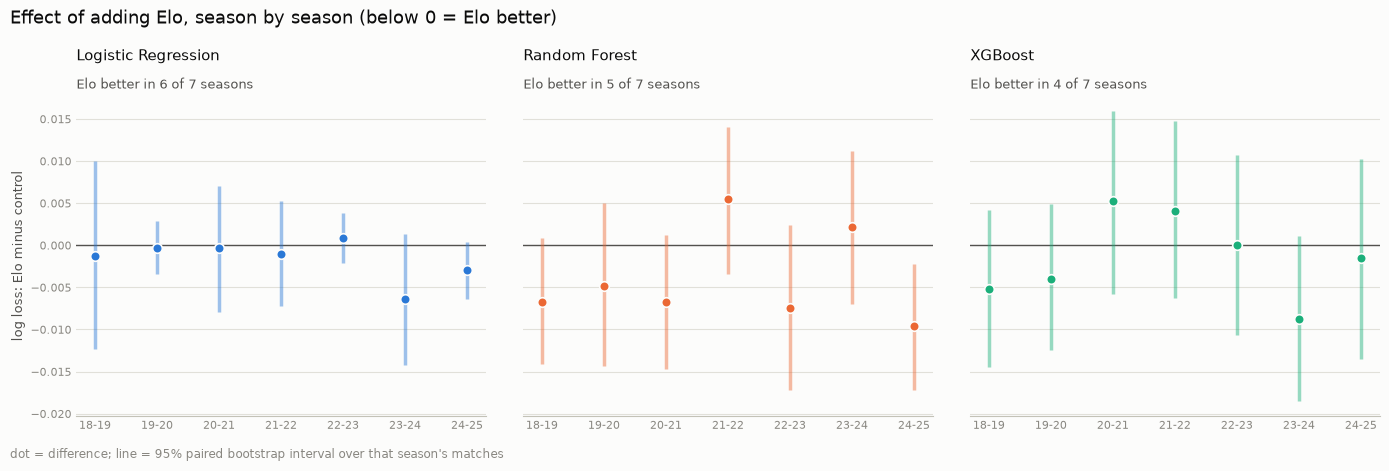

In [16]:
boot = seasonal_bootstrap(predictions, PAIRS, n_resamples=N_RESAMPLES)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), facecolor=SURFACE, sharey=True)
x = np.arange(len(BACKTEST_SEASONS))
for ax, (elo, model) in zip(axes, PAIRS):
    rows = boot[boot["a"] == elo].set_index("season").loc[list(BACKTEST_SEASONS)]
    ax.axhline(0, color=INK_2, linewidth=1, zorder=1)
    ax.vlines(x, rows["ci_low"], rows["ci_high"], color=MODEL_COLORS[model], linewidth=2.5, alpha=0.45, zorder=2)
    ax.scatter(x, rows["difference"], s=48, color=MODEL_COLORS[model], edgecolors=SURFACE, linewidths=1.2, zorder=3)
    better = int((rows["difference"] < 0).sum())
    ax.set_xticks(x, [SEASON_LABELS[s][2:] for s in BACKTEST_SEASONS], fontsize=8, color=INK_2)
    style_axes(ax)
    set_title(ax, model, f"Elo better in {better} of {len(x)} seasons", size=11)
axes[0].set_ylabel("log loss: Elo minus control", fontsize=9, color=INK_2)
fig.suptitle("Effect of adding Elo, season by season (below 0 = Elo better)", x=0.01, ha="left", fontsize=13,
             color=INK)
fig.text(0.01, 0.005, "dot = difference; line = 95% paired bootstrap interval over that season's matches",
         fontsize=8.5, color=MUTED)
fig.tight_layout(w_pad=2.5, rect=(0, 0.03, 1, 1))
save_figure(fig, "42_elo_by_season.png")
plt.show()

**Interpretation**

- **Logistic Regression:** better with Elo in 6 of 7 seasons, but by tiny amounts (most within
  ±0.0013; the largest gain is −0.0064 in 2023-24).
- **Random Forest:** better in 5 of 7 seasons, with larger swings, from −0.0096 (2024-25) to
  +0.0054 (2021-22).
- **XGBoost:** better in only 4 of 7, ranging from −0.0087 to +0.0053.
- **Within a single season the effect cannot be distinguished from noise.** 20 of the 21 seasonal
  intervals include 0; the exception is Random Forest in 2024-25.

### 8d. Uncertainty, consistency and multiple comparisons

Three models are compared, so three chances to find a "significant" improvement by luck. Two
corrections are used:
- **Bonferroni-adjusted intervals:** besides the usual 95% paired bootstrap interval, each pooled
  difference gets a 98.3% interval (`1 - 0.05 / 3`), so the three comparisons together keep a 5%
  error rate.
- **Holm-adjusted sign tests:** the season-level sign-test p-values are adjusted across the three
  models.

The match-level bootstrap treats matches as independent, which overstates precision (matches in
a season share conditions). The season-level view treats each season as one observation:
- **Seasons better / worse:** in how many of the seven seasons the Elo arm had the lower loss.
- **t-interval:** the mean seasonal difference with a 95% t-interval (6 degrees of freedom).
- **Leave one season out:** the range of the pooled difference when each season is dropped in
  turn.

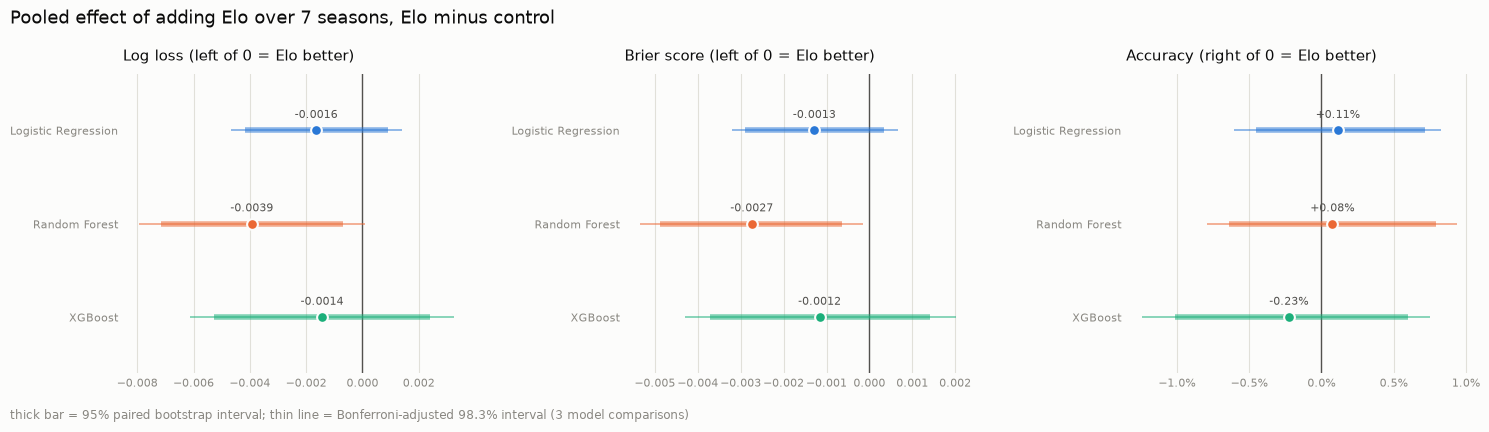

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), facecolor=SURFACE)
y = np.arange(len(MODELS))[::-1]
for ax, metric, title in zip(axes, ("log_loss", "brier", "accuracy"),
                             ("Log loss (left of 0 = Elo better)", "Brier score (left of 0 = Elo better)",
                              "Accuracy (right of 0 = Elo better)")):
    table = tables[metric]
    ax.axvline(0, color=INK_2, linewidth=1, zorder=1)
    for yi, model in zip(y, MODELS):
        r = table.loc[model]
        ax.hlines(yi, r["bootstrap_adj_ci_low"], r["bootstrap_adj_ci_high"], color=MODEL_COLORS[model],
                  linewidth=1.2, alpha=0.6, zorder=2)
        ax.hlines(yi, r["bootstrap_ci_low"], r["bootstrap_ci_high"], color=MODEL_COLORS[model], linewidth=4,
                  alpha=0.55, zorder=2)
        ax.scatter(r["difference"], yi, s=60, color=MODEL_COLORS[model], edgecolors=SURFACE, linewidths=1.5, zorder=3)
        fmt = "{:+.2%}" if metric == "accuracy" else "{:+.4f}"
        ax.annotate(fmt.format(r["difference"]), (r["difference"], yi), xytext=(0, 9), textcoords="offset points",
                    ha="center", fontsize=8, color=INK_2)
    ax.set_yticks(y, MODELS, fontsize=9, color=INK_2)
    ax.set_ylim(-0.6, len(MODELS) - 0.4)
    if metric == "accuracy":
        ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    style_axes(ax, grid="x")
    ax.spines["bottom"].set_visible(False)
    set_title(ax, title, size=10.5)
fig.suptitle("Pooled effect of adding Elo over 7 seasons, Elo minus control", x=0.01, ha="left", fontsize=13,
             color=INK)
fig.text(0.01, 0.005, "thick bar = 95% paired bootstrap interval; thin line = Bonferroni-adjusted 98.3% interval "
         "(3 model comparisons)", fontsize=8.5, color=MUTED)
fig.tight_layout(w_pad=3, rect=(0, 0.04, 1, 1))
save_figure(fig, "43_elo_pooled_intervals.png")
plt.show()

In [18]:
fmt = {"control": "{:.4f}", "elo": "{:.4f}", "difference": "{:+.4f}", "seasons": "{:.0f}", "seasons_better": "{:.0f}",
       "seasons_worse": "{:.0f}", "sign_test_p": "{:.3f}", "sign_test_p_holm": "{:.3f}", "mean_difference": "{:+.4f}",
       "season_t_low": "{:+.4f}", "season_t_high": "{:+.4f}", "leave_one_out_min": "{:+.4f}",
       "leave_one_out_max": "{:+.4f}", "bootstrap_ci_low": "{:+.4f}", "bootstrap_ci_high": "{:+.4f}",
       "bootstrap_adj_ci_low": "{:+.4f}", "bootstrap_adj_ci_high": "{:+.4f}"}
for metric in ("log_loss", "brier"):
    display(tables[metric].drop(columns="metric").style.format(fmt).set_caption(f"{metric}: Elo minus control"))

,control,elo,difference,seasons,seasons_better,seasons_worse,sign_test_p,mean_difference,season_t_low,season_t_high,leave_one_out_min,leave_one_out_max,sign_test_p_holm,bootstrap_ci_low,bootstrap_ci_high,bootstrap_adj_ci_low,bootstrap_adj_ci_high
model,,,,,,,,,,,,,,,,,
Logistic Regression,0.9834,0.9818,-0.0016,7,6,1,0.125,-0.0016,-0.0039,+0.0006,-0.0021,-0.0009,0.375,-0.0042,+0.0009,-0.0047,+0.0014
Random Forest,0.9829,0.9790,-0.0039,7,5,2,0.453,-0.0039,-0.0091,+0.0012,-0.0055,-0.0030,0.906,-0.0072,-0.0007,-0.0079,+0.0001
XGBoost,0.9808,0.9794,-0.0014,7,4,3,1.000,-0.0014,-0.0061,+0.0032,-0.0025,-0.0002,1.000,-0.0053,+0.0024,-0.0061,+0.0033


,control,elo,difference,seasons,seasons_better,seasons_worse,sign_test_p,mean_difference,season_t_low,season_t_high,leave_one_out_min,leave_one_out_max,sign_test_p_holm,bootstrap_ci_low,bootstrap_ci_high,bootstrap_adj_ci_low,bootstrap_adj_ci_high
model,,,,,,,,,,,,,,,,,
Logistic Regression,0.5854,0.5841,-0.0013,7,5,2,0.453,-0.0013,-0.0026,+0.0001,-0.0016,-0.0009,1.000,-0.0029,+0.0003,-0.0032,+0.0007
Random Forest,0.5854,0.5826,-0.0027,7,5,2,0.453,-0.0027,-0.0060,+0.0006,-0.0036,-0.0022,1.000,-0.0049,-0.0006,-0.0053,-0.0001
XGBoost,0.5842,0.5831,-0.0012,7,4,3,1.000,-0.0012,-0.0037,+0.0014,-0.0018,-0.0005,1.000,-0.0037,+0.0014,-0.0043,+0.0020


**Interpretation**

- **The match-level evidence is borderline.**
  - Random Forest's 95% bootstrap interval (−0.0072 to −0.0007) excludes 0, but its
    Bonferroni-adjusted interval (−0.0079 to +0.0001) just reaches it.
  - Logistic Regression (−0.0042 to +0.0009) and XGBoost (−0.0053 to +0.0024) include 0 even
    before correction.
- **The season-level checks are weaker still.**
  - Every season-level t-interval includes 0.
  - Sign tests give p = 0.125 (Logistic Regression, 6 of 7), 0.45 (Random Forest) and 1.0
    (XGBoost); after Holm adjustment 0.38, 0.91 and 1.0.
- **Robustness is the encouraging part.**
  - Every leave-one-season-out pooled difference is negative for all three models (Logistic
    Regression −0.0021 to −0.0009, Random Forest −0.0055 to −0.0030, XGBoost −0.0025 to −0.0002).
    No single season creates the pooled gain.
  - All six pooled loss differences (three models × log loss and Brier) point the same way. They
    are not independent evidence, though: same fixtures, same Elo columns.
- **Overall:** a small, consistent-looking improvement in probability quality that this sample
  cannot confirm after accounting for multiple comparisons.

### 8e. Matches with a newly promoted club

Promoted clubs are where Elo could help most: the existing features have no previous season for
them (`prev_season_*` is missing and `promoted` is set), while Elo gives them the rating of the
clubs they replaced, updated after every match. This splits the common fixtures into those with
at least one promoted (or returning) club and the rest.

In [19]:
groups = subgroup_metrics(predictions, features)
sub = groups[groups["forecast"].isin(MODELS + ELO_LABELS)].pivot(index="forecast", columns="promoted_club",
                                                                   values="log_loss")
sub = sub.rename(columns={True: "with promoted club", False: "without"}).loc[order[:6]]
counts = groups.groupby("promoted_club")["matches"].first()
print(f"Fixtures with a promoted club: {counts[True]:,}; without: {counts[False]:,}")
display(sub.style.format("{:.4f}").set_caption("Pooled log loss by subgroup"))

sub_intervals = subgroup_intervals(predictions, features, n_resamples=N_RESAMPLES)
sub_intervals["subgroup"] = sub_intervals["promoted_club"].map({True: "with promoted club", False: "without"})
sub_intervals["model"] = sub_intervals["b"]
sub_intervals[["subgroup", "model", "matches", "difference", "ci_low", "ci_high", "adj_ci_low", "adj_ci_high"]] \
    .style.format({"difference": "{:+.4f}", "ci_low": "{:+.4f}", "ci_high": "{:+.4f}", "adj_ci_low": "{:+.4f}",
                   "adj_ci_high": "{:+.4f}", "matches": "{:,}"}).hide(axis="index").set_caption(
    "Log loss, Elo minus control, by subgroup (95% and Bonferroni-adjusted intervals)")

Fixtures with a promoted club: 756; without: 1,901


promoted_club,without,with promoted club
forecast,,
Logistic Regression,0.9865,0.9758
Logistic Regression + Elo,0.9843,0.9754
Random Forest,0.9810,0.9876
Random Forest + Elo,0.9776,0.9825
XGBoost,0.9813,0.9797
XGBoost + Elo,0.9785,0.9815


subgroup,model,matches,difference,ci_low,ci_high,adj_ci_low,adj_ci_high
without,Logistic Regression,"1,901",-0.0021,-0.0051,+0.0008,-0.0057,+0.0014
without,Random Forest,"1,901",-0.0035,-0.0073,+0.0003,-0.0081,+0.0011
without,XGBoost,"1,901",-0.0027,-0.0074,+0.0018,-0.0084,+0.0027
with promoted club,Logistic Regression,756,-0.0004,-0.0053,+0.0045,-0.0062,+0.0056
with promoted club,Random Forest,756,-0.0051,-0.0115,+0.0011,-0.0127,+0.0026
with promoted club,XGBoost,756,+0.0018,-0.0055,+0.0092,-0.0072,+0.0109


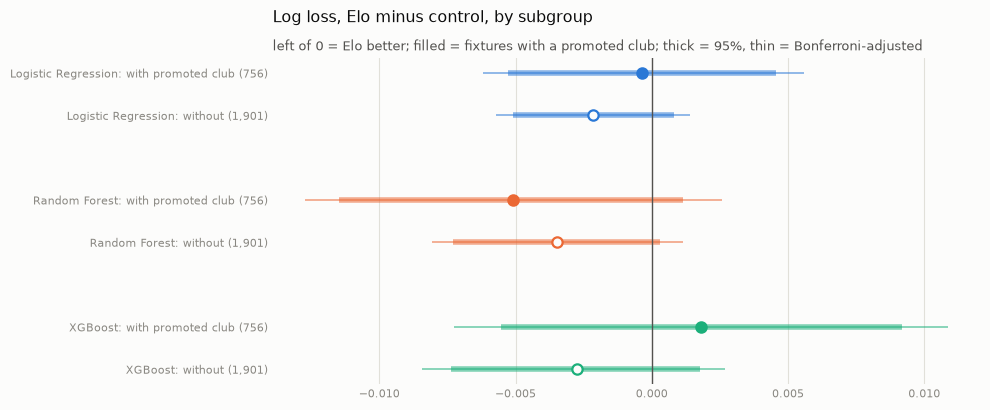

In [20]:
fig, ax = plt.subplots(figsize=(10, 4.2), facecolor=SURFACE)
labels, positions = [], []
for i, (elo, model) in enumerate(PAIRS):
    for j, flag in enumerate((True, False)):
        r = sub_intervals[(sub_intervals["b"] == model) & (sub_intervals["promoted_club"] == flag)].iloc[0]
        yi = -(i * 3 + j)
        ax.hlines(yi, r["adj_ci_low"], r["adj_ci_high"], color=MODEL_COLORS[model], linewidth=1.2, alpha=0.6)
        ax.hlines(yi, r["ci_low"], r["ci_high"], color=MODEL_COLORS[model], linewidth=4, alpha=0.55)
        ax.scatter(r["difference"], yi, s=55, color=MODEL_COLORS[model] if flag else SURFACE,
                   edgecolors=MODEL_COLORS[model], linewidths=1.6, zorder=3)
        labels.append(f"{model}: {'with promoted club' if flag else 'without'} ({r['matches']:,})")
        positions.append(yi)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_yticks(positions, labels, fontsize=8.5, color=INK_2)
style_axes(ax, grid="x")
ax.spines["bottom"].set_visible(False)
set_title(ax, "Log loss, Elo minus control, by subgroup", "left of 0 = Elo better; filled = fixtures with a promoted "
          "club; thick = 95%, thin = Bonferroni-adjusted", size=11.5)
fig.tight_layout()
save_figure(fig, "44_elo_promoted_subgroup.png")
plt.show()

**Interpretation**

- **Elo does not help most where it might be expected to.** In the 756 fixtures with a promoted
  club:
  - Logistic Regression: −0.0004 (vs −0.0021 elsewhere);
  - Random Forest: −0.0051 (vs −0.0035);
  - XGBoost: +0.0018 (vs −0.0027).
- **All six intervals include 0,** so there is no evidence of a promoted-club benefit.
- **This makes sense.** A promoted club's entry rating is nearly the same every year (about
  1393–1419), so at first it carries little more than the existing `promoted` flag. Elo only
  becomes club-specific as the promoted club plays, and by then the season-to-date features also
  have data.

## 9. Limitations

- **Fixed Elo settings.** K = 20, home advantage 60 and 30% regression are textbook-style
  defaults that were not tuned. Other values (or a margin-of-victory multiplier) might carry more
  information. Tuning them would have to happen inside past-only nested validation, which this
  experiment does not do.
- **Serie A only.** Promoted clubs' Serie B results and European or cup matches are not in the
  data, so the ratings miss information that a full Elo system (e.g. one covering all leagues)
  would have.
- **Entry policy.** Promoted clubs are assumed to be as strong as the clubs they replace. In
  reality some are much stronger or weaker, and the 2004-05 expansion briefly lowered the league
  average to about 1493.
- **Seven seasons, about 2,660 matches.** Season-to-season variation is large compared with the
  effects measured here, so small real effects can stay hidden and small apparent effects can be
  noise.
- **Match-level intervals are optimistic:** they treat matches as independent. The season-level
  checks are coarser but more honest about this.
- **The grids were set in commit 7**, partly after looking at 2025-26, as noted in notebook 06.
  This affects both arms equally.

## 10. Recommendation

The decision rule was written down in `src/elo_experiment.py` **before** the experiment was run.
Elo is recommended for a production model only if all three hold for that model:
1. pooled log loss improves, with a Bonferroni-adjusted paired bootstrap interval below 0;
2. the improvement appears in at least 5 of the 7 seasons;
3. the pooled improvement survives leaving out any one season.

In [21]:
rule = decision(predictions, n_resamples=N_RESAMPLES)
rule.style.format({"log_loss_difference": "{:+.4f}"})

,log_loss_difference,adjusted_interval_below_zero,seasons_better,enough_seasons,survives_leave_one_out,recommend_elo
model,,,,,,
Logistic Regression,-0.0016,False,6,True,True,False
Random Forest,-0.0039,False,5,True,True,False
XGBoost,-0.0014,False,4,False,True,False


**Recommendation: do not add Elo to the production models yet.**

- **No model meets the decision rule.**

  | Model | Fails on |
  |---|---|
  | Logistic Regression | Adjusted interval (−0.0047 to +0.0014) |
  | Random Forest | Adjusted interval (upper end +0.0001) |
  | XGBoost | Adjusted interval, and only 4 of 7 seasons better |

  All three pass the leave-one-season-out check.
- **What the evidence supports:** with fixed, untuned settings, Elo features lowered log loss and
  Brier score slightly for every model, consistently enough that no single season drives it.
  The effect is at most about 0.004 log loss and does not improve accuracy or macro F1.
- **What it does not support:**
  - a claim that Elo improves predictions;
  - any benefit for promoted clubs.
- **Suggested next steps** (not done here):
  1. Keep `src/elo.py` and the `+ Elo` feature sets as the leading candidate, with the settings
     frozen.
  2. Confirm on a season this experiment has not used, with the same pre-registered rule, before
     changing production. The candidate is Random Forest + Elo, the largest and most stable gain.
  3. If Elo settings are to be tuned (K, home advantage, regression), do it inside past-only
     nested validation only.
- **Unchanged:** the saved production models, the Streamlit app and the established
  equal-weight training.